# 1. Data Loading & Cleaning

In [ ]:
import pandas as pd 

df = pd.read_csv('amazon_final.csv')

print(df.head())

   rating                                       title_review  \
0     3.0     Great for someone who needs help with gripping   
1     4.0    Needs a better protective cover. Cuts very well   
2     5.0                                     Perfect peeler   
3     5.0                                         Good stuff   
4     5.0  This is not merely a peeler, this is a very sh...   

                                                text images        asin  \
0  It is a sharp peeler but a little to bulky for...     []  B00004OCIP   
1  nice handy peeler. The blade comes sharp and p...     []  B00004OCIP   
2  My second. I accidentally threw the first out ...     []  B00004OCIP   
3  As always with OXO, this is good stuff. Sturdy...     []  B00004OCIP   
4  By far the sharpest, easiest to use peeler I h...     []  B00004OCIP   

  parent_asin                       user_id      timestamp  helpful_vote  \
0  B00004OCIP  AHBIGTZCJOWAGUEGZPJ4A7YGBDYQ  1475558906000             0   
1  B00004OCI

In [ ]:
# Check duplicate rows

df[df.duplicated(keep=False)]

,rating,title_review,text,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,main_category,title_product,average_rating,rating_number,price,store,categories,details


There are 6 rows forming 3 pairs of identical reviews. Remove one duplicate from each pair, keeping one copy of each review.

In [8]:
# Remove duplicate rows, keeping the first copy of each review
df = df.drop_duplicates().reset_index(drop=True)

In [9]:
# Count missing values in each column
df.isna().sum()

rating                 0
title_review           3
text                   5
images                 0
asin                   0
parent_asin            0
user_id                0
timestamp              0
helpful_vote           0
verified_purchase      0
main_category         63
title_product          0
average_rating         0
rating_number          0
price                615
store                  0
categories             0
details                0
dtype: int64

--> Missing values in title_review, text, main_category, and price do not affect rating-based analysis, so these rows are retained. The images column is excluded because image analysis is outside the project scope.

In [11]:
df = df.drop(columns=['images'])

In [12]:
# Check column data types
df.dtypes

rating               float64
title_review             str
text                     str
asin                     str
parent_asin              str
user_id                  str
timestamp              int64
helpful_vote           int64
verified_purchase       bool
main_category            str
title_product            str
average_rating       float64
rating_number          int64
price                float64
store                    str
categories               str
details                  str
dtype: object

In [13]:
# Show rows with missing or invalid ratings
df[~df['rating'].isin([1, 2, 3, 4, 5])]

,rating,title_review,text,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,main_category,title_product,average_rating,rating_number,price,store,categories,details


--> All ratings are valid and fall within the expected range of 1 to 5 stars.

In [14]:
# Check for negative prices, helpful votes, or rating counts
df[(df['price'] < 0) | (df['helpful_vote'] < 0) | (df['rating_number'] < 0)]

,rating,title_review,text,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,main_category,title_product,average_rating,rating_number,price,store,categories,details


-> No negative values were found in price, helpful_vote, or rating_number.

In [15]:
# Check the final number of rows, columns, and unique products
print("Reviews:", len(df))
print("Columns:", df.shape[1])
print("Products:", df['parent_asin'].nunique())

Reviews: 9739
Columns: 17
Products: 100


--> After basic cleaning and validation, the dataset contains 9,739 reviews across 100 products and 17 columns. Exact duplicates have been removed, ratings are valid, and no negative prices or counts were found. The dataset is ready for exploratory data analysis.

# 2. Exploratory Data Analysis

### Rating Distribution

In [17]:
# Count reviews and calculate the percentage for each rating
rating_distribution = df['rating'].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0).sort_index().to_frame(name='review_count')
rating_distribution['percentage'] = (
    rating_distribution['review_count'] / len(df) * 100
).round(2)

rating_distribution

,review_count,percentage
rating,,
1,553,5.68
2,304,3.12
3,474,4.87
4,946,9.71
5,7462,76.62


Matplotlib is building the font cache; this may take a moment.


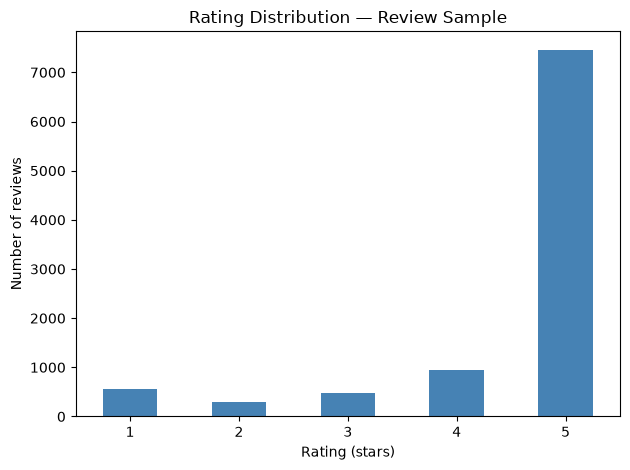

In [18]:
# Plot the distribution of ratings in the review sample
import matplotlib.pyplot as plt

rating_distribution['review_count'].plot(
    kind='bar', color='steelblue', rot=0
)
plt.title('Rating Distribution — Review Sample')
plt.xlabel('Rating (stars)')
plt.ylabel('Number of reviews')
plt.tight_layout()
plt.show()

In [19]:
# Compare positive and negative reviews for each product
product_summary = df.groupby('parent_asin').agg(
    title_product=('title_product', 'first'),
    review_count=('rating', 'size'),
    sample_average_rating=('rating', 'mean'),
    five_star_pct=('rating', lambda x: x.eq(5).mean() * 100),
    low_rating_pct=('rating', lambda x: x.le(2).mean() * 100)
).round(2)

# Show products with at least 30 sampled reviews, ranked by low-rating share
product_summary[product_summary['review_count'] >= 30].sort_values(
    'low_rating_pct', ascending=False
).head(10)

,title_product,review_count,sample_average_rating,five_star_pct,low_rating_pct
parent_asin,,,,,
B08Q349KSF,"My Pillow Classic Series [Std/Queen, Medium Fill]",49,3.53,46.94,30.61
B07SRD41CL,"MyPillow Premium Bed Pillow King, Most Firm",30,3.70,60.00,30.00
B08BHWQWBD,Kitchen Mama Auto Electric Can Opener: Open Yo...,42,3.83,59.52,26.19
B07N1F94DD,Utopia Bedding Fleece Blanket King Size Grey 3...,32,3.88,59.38,25.00
B000CO89T8,"Mr. Coffee Mug Warmer for Coffee and Tea, Port...",56,3.95,58.93,23.21
B08MBWQQFY,1000 Thread Count 100% Egyptian Cotton Fitted ...,31,3.94,61.29,22.58
B00C351GBC,Shark SV1106 Navigator Freestyle Upright Bagle...,33,3.91,57.58,21.21
B08XYD548C,Beckham Hotel Collection Bed Pillows Standard ...,123,4.04,60.98,18.70
B01DAI5BZ2,BLACK+DECKER dustbuster Cordless Handheld Vacu...,38,4.13,60.53,18.42


Products with at least 30 sampled reviews were ranked by their share of one- and two-star reviews. This exploratory threshold limits comparisons based on very small review counts; it is not an Amazon standard or a guarantee of representativeness. 

--> Several products show substantial shares of both five-star and low-rated reviews, suggesting contrasting customer experiences that average ratings alone may obscure.

### Initial Exploration of Customer Complaints
Beckham pillows was selected first because it has the most sampled reviews among the 10 products shown (123), including 23 low-rated reviews (18.70%).

In [25]:
# Show all low-rated reviews for Beckham pillows
selected_product = 'B08XYD548C'

with pd.option_context('display.max_colwidth', None):
    display(
        df.loc[
            df['parent_asin'].eq(selected_product) & df['rating'].le(2),
            ['rating', 'title_review', 'text']
        ]
    )

,rating,title_review,text
8948,2.0,No improvement,This was not worth the money. Its a pillow. It didn't keep me cooler.
8955,1.0,Onley received one pillow,"Onley got one pillow, was two in the order"
8959,1.0,First order - awesome - Second order - GARBAGE!,"I ordered these pillows some time ago and they were wonderful and well worth the money. As a result of this experience, i came back to order another set and did so in Feb-2021. These are simply NOT THE SAME PILLOW! I treated them exactly the same as the first order and the recent order was DISAPPOINTING to say the least They are lumpy and impossible to get a good night's sleep! Many companies seem to fall into the trap of trying to sell a cheaper and sub par product to increase their profit margin after they receive several good reviews. I can't be sure but this seems to be the case for this product. I CANNOT RECOMMEND THIS PRODUCT - was great initially but has changed and IS NOT WORTH THE COST! DO NOT BUY!"
8960,1.0,Not worth the money,"These pillows were lumpy, they are nowhere near a “down alternative” except to say I guess that they are an alternative material than down but they’re nothing like it in feeling or quality. These pillows do not hold their shape, they get warm quickly and stay that way, and provide support when on stomach but definitely not something comfortable for side or back sleepers."
8966,2.0,Goes Flat,"Once aired out they got very thick, but there is NO support. When you lay on them they are just flat. Very disappointed for the price."
8973,1.0,Disappointed,Surprised of what these turned out to be.
8981,1.0,"Awful, no support",Awful. Just terrible. 3 horrible nights sleeping. Can’t say it was all the pillows but haven’t been that restless in 20 years. Absolutely zero support. Would have had more support from a roll of paper towels.
8983,1.0,SUPER SUPER LOW LOFT,This the fifth time I ordered these pillows. Loft has been lower and lower. Have tried every method to get them to fluff. Waste of money. Time to find something different. Pillow shopping is a chore.
8986,2.0,If you like a hard pillow this is for you,Very very firm and I only ordered the medium. It hurt my neck and my husband tried as well and it also caused him neck pain. Returned.
8989,2.0,Does not give support,First 3 days I thought I had found the perfect pillow. After that it has gone at as can be no fluff or comfort. I might as well have bought a 10.00 pillow at Walmart it last longer. Very disappointed


### Customer Complaint Analysis (NLP)

In [26]:
# Select low-rated reviews and combine their titles and text
negative_reviews = df.loc[
    df['parent_asin'].eq(selected_product) & df['rating'].le(2)
].copy()

negative_reviews['review_text'] = (
    negative_reviews['title_review'].fillna('') + ' ' +
    negative_reviews['text'].fillna('')
).str.strip()

In [27]:
# Remove HTML, decode special characters, and normalize whitespace
import html
import re

def clean_review(text):
    text = html.unescape(text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = text.lower()
    return re.sub(r'\s+', ' ', text).strip()

negative_reviews['clean_text'] = (
    negative_reviews['review_text'].apply(clean_review)
)

negative_reviews[['review_text', 'clean_text']].head()

,review_text,clean_text
8948,No improvement This was not worth the money. I...,no improvement this was not worth the money. i...
8955,Onley received one pillow Onley got one pillow...,onley received one pillow onley got one pillow...
8959,First order - awesome - Second order - GARBAGE...,first order - awesome - second order - garbage...
8960,"Not worth the money These pillows were lumpy, ...","not worth the money these pillows were lumpy, ..."
8966,"Goes Flat Once aired out they got very thick, ...","goes flat once aired out they got very thick, ..."


--> An initial reading of the low-rated reviews suggested five complaint themes: insufficient support or flattening, lumpiness, heat retention, size discrepancies, and missing items. These themes were used to define the initial keyword-based classification rules.

In [28]:
# Define initial complaint patterns for pillow reviews
complaint_patterns = {
    'support_flattening': r'no support|zero support|0 support|not supportive|no neck support|flat|low loft',
    'lumpiness': r'lumpy|lumpiness',
    'heat': r'not cooling|no cooling|hot|warm|heat|cooler',
    'size': r'standard size|standard pillows|smaller|queen sized cases',
    'missing_item': r'only got one pillow|onley got one pillow|only received one pillow|onley received one pillow'
}

# Assign each review to any matching complaint themes
for theme, pattern in complaint_patterns.items():
    negative_reviews[theme] = negative_reviews['clean_text'].str.contains(
        pattern, regex=True, na=False
    )

# Count reviews mentioning each theme
theme_columns = list(complaint_patterns)

complaint_summary = (
    negative_reviews[theme_columns].sum()
    .sort_values(ascending=False)
    .to_frame('review_count')
)

complaint_summary['percentage'] = (
    complaint_summary['review_count'] / len(negative_reviews) * 100
).round(2)

complaint_summary

,review_count,percentage
support_flattening,12,52.17
heat,6,26.09
lumpiness,4,17.39
size,3,13.04
missing_item,1,4.35


Initial keyword-based analysis flagged support or flattening concerns in 52.17% of the 23 low-rated reviews, followed by heat-related mentions (26.09%), lumpiness (17.39%), size (13.04%), and missing items (4.35%). These preliminary results require manual validation. Reviews may match multiple themes.

In [30]:
# Inspect 12 reviews matched to the support and flattening theme
with pd.option_context('display.max_colwidth', None):
    display(
        negative_reviews.loc[
            negative_reviews['support_flattening'],
            ['title_review', 'text']
        ]
    )

,title_review,text
8966,Goes Flat,"Once aired out they got very thick, but there is NO support. When you lay on them they are just flat. Very disappointed for the price."
8981,"Awful, no support",Awful. Just terrible. 3 horrible nights sleeping. Can’t say it was all the pillows but haven’t been that restless in 20 years. Absolutely zero support. Would have had more support from a roll of paper towels.
8983,SUPER SUPER LOW LOFT,This the fifth time I ordered these pillows. Loft has been lower and lower. Have tried every method to get them to fluff. Waste of money. Time to find something different. Pillow shopping is a chore.
8993,Terrible and 0 support.,Terrible pillow. How does it have 4.5 stars?? Unless you like to be smothered by your pillow. 0 support. Puffs around your face. Returned!
8994,This pillow sucks,I should've read the reviews. Super lumpy and flat
8996,NOT FOR SIDE SLEEPERS,"Bought this because it was on Amazon’s page for supporting small business. It is awful. My neck is in such a crick which I believe is due to this pillow. After seeing the numerous 5 star reviews, I was fooled into thinking this pillow would be perfect. Not so. Not even close. My wife (also a side sleeper) slept on it for about 3 nights and said she hated it. I fooled myself into sleeping on it for a couple of months now and I’m giving up. My neck hurts and I fill this pillow doesn’t support my neck even the least bit. It’s either too high or too flat depending on how I fluff it and I find myself adjusting it at least a couple of times a night."
9002,So not what they say,"so I heard these pillows were top sellers for 2022. they were supposed to be queen sized pillows that were cooling and gave awesome support. I unboxed the pillows, allowed them to air out for 24 hours then slipped them into my queen sized pillow cases - uhm stop right there, these are plain old every day standard pillows (my queen sized cases dwarf the pillows) that go flat when you put your head on them. They are NOT cooling, they actually heat up as you lay on them. I drank the kool aid and got these and if they weren't so expensive I would donate them to a shelter. I got these because chemo has brought back the hot flashes and I NEED a good cooling pillow."
9006,"gets hot, no support","nothing like the discription on the site, very poor pillow for support, comfort"
9018,Looks Firm but flat,"Pillows look so full and firm, but when you lay your head on it . flat not firm"
9030,Horrible!,"I am not picky, but these pillows have no support. I put my head on the pillow and my head went straight to mattress. Shocked how many have been purchased, but more I look…seems like the pillows use to be better and now have downgraded greatly in quality. Returning asap!"


--> Manual inspection confirmed that all 12 matched reviews describe insufficient support or flattening. No false positives were identified in this group. Further checks are needed to identify relevant reviews missed by the rules.

In [31]:
# Inspect reviews not matched to the support and flattening theme
with pd.option_context('display.max_colwidth', None):
    display(
        negative_reviews.loc[
            ~negative_reviews['support_flattening'],
            ['title_review', 'text']
        ]
    )

,title_review,text
8948,No improvement,This was not worth the money. Its a pillow. It didn't keep me cooler.
8955,Onley received one pillow,"Onley got one pillow, was two in the order"
8959,First order - awesome - Second order - GARBAGE!,"I ordered these pillows some time ago and they were wonderful and well worth the money. As a result of this experience, i came back to order another set and did so in Feb-2021. These are simply NOT THE SAME PILLOW! I treated them exactly the same as the first order and the recent order was DISAPPOINTING to say the least They are lumpy and impossible to get a good night's sleep! Many companies seem to fall into the trap of trying to sell a cheaper and sub par product to increase their profit margin after they receive several good reviews. I can't be sure but this seems to be the case for this product. I CANNOT RECOMMEND THIS PRODUCT - was great initially but has changed and IS NOT WORTH THE COST! DO NOT BUY!"
8960,Not worth the money,"These pillows were lumpy, they are nowhere near a “down alternative” except to say I guess that they are an alternative material than down but they’re nothing like it in feeling or quality. These pillows do not hold their shape, they get warm quickly and stay that way, and provide support when on stomach but definitely not something comfortable for side or back sleepers."
8973,Disappointed,Surprised of what these turned out to be.
8986,If you like a hard pillow this is for you,Very very firm and I only ordered the medium. It hurt my neck and my husband tried as well and it also caused him neck pain. Returned.
8989,Does not give support,First 3 days I thought I had found the perfect pillow. After that it has gone at as can be no fluff or comfort. I might as well have bought a 10.00 pillow at Walmart it last longer. Very disappointed
9012,Not for me.,"I found the pillows only ok in support, but still ran hot for me. Just not for me, so I returned."
9029,Ended up returning these,"I get nightly migraines and have trouble finding a pillow that works well for me. I can't tolerate memory foam and anything too hard causes head and ear pain. I also need something cooling and all those type pillows always seem to be memory foam and absurdly expensive. This pillow was advertised as cooling and comfortable so I figured I'd give it a shot since it wasn't that expensive.<br /><br />When the box arrived, I was shocked at how heavy it was. The pillows are vacuum packed and tightly rolled. You have to carefully cut the sealed plastic and let them plump up for about an hour. They are surprisingly heavy pillows. They don't shift around at night at all unless you purposely move them. Do not expect these to be firm pillows. They are what I call 'poofy'. You lay your head on them and immediately sink into it. Initially I thought these pillows would be okay. The first few nights were fine and I slept well.<br /><br />Unfortunately after giving them ten days, they got worse. They lost all poof entirely and my head sank completely to the bed. My ear actually hurt during the night and I had to toss around and try to plump the pillow up several times during the night. In addition, they are very hot pillows. They have no cooling at all and are actually hotter to sleep on then the original ordinary pillows I was replacing. I ended up returning them."
9032,Great for 2 months then garbage,I was super happy with these at first. I'm a side sleep and my neck pain went away. But it only took two months and they are both breaking down and super lumpy.


Manual inspection identified three missed reviews (8960, 8989, and 9029) describing loss of shape, insufficient support, or loss of loft. Their expressions were added to refine the classification rule.

In [32]:
# Add expressions found in the three missed reviews
complaint_patterns['support_flattening'] += (
    r'|do not hold their shape|does not give support'
    r'|no fluff|lost all poof|head sank completely'
)

# Update the support and flattening labels
negative_reviews['support_flattening'] = (
    negative_reviews['clean_text'].str.contains(
        complaint_patterns['support_flattening'], regex=True, na=False
    )
)

In [33]:
# Recalculate complaint counts and percentages after refining the rule
complaint_summary = (
    negative_reviews[theme_columns].sum()
    .sort_values(ascending=False)
    .to_frame('review_count')
)

complaint_summary['percentage'] = (
    complaint_summary['review_count'] / len(negative_reviews) * 100
).round(2)

complaint_summary

,review_count,percentage
support_flattening,15,65.22
heat,6,26.09
lumpiness,4,17.39
size,3,13.04
missing_item,1,4.35


After refining the rules, support or flattening concerns were identified in 15 of the 23 low-rated reviews (65.22%), making this the most frequent theme. The other themes remain preliminary and require manual validation. Reviews may belong to multiple themes.

Support and flattening concerns were the leading theme, identified in 65.22% of the 23 low-rated reviews. Heat-related mentions followed at 26.09%, pending validation. These findings suggest prioritizing a product performance review with the seller or supplier, focusing on support, shape retention, and cooling claims.

### Seller Engagement & Escalation Framework

| Step | Proposed action |
|---|---|
| **1. Flag** | Flag Beckham pillows for investigation based on contrasting ratings and recurring support/flattening complaints. |
| **2. Engage** | Share the findings with the seller and request an investigation and improvement plan within an agreed timeframe. |
| **3. Monitor** | Track support-related complaints in new reviews, considering both their proportion and review volume. |
| **4. Escalate** | If concerns persist despite follow-up, escalate for a listing review, including potential restrictions or removal under applicable marketplace policies. |

This proposed framework aims to improve customer experience while giving the seller an opportunity to address reported concerns. The current sample supports further investigation, not an immediate removal decision.

# Dataset Preparation for Tableau

In [36]:
# Calculate the percentage of each rating for every product
rating_proportions = pd.crosstab(
    df['parent_asin'],
    df['rating'],
    normalize='index'
).reindex(columns=[1, 2, 3, 4, 5], fill_value=0).mul(100).round(2)

rating_proportions.columns = [
    'one_star_pct', 'two_star_pct', 'three_star_pct',
    'four_star_pct', 'five_star_pct'
]

# Add rating proportions to the product summary
product_summary = product_summary.drop(
    columns=['five_star_pct'], errors='ignore'
).join(rating_proportions)

product_summary.head()

,title_product,review_count,sample_average_rating,low_rating_pct,one_star_pct,two_star_pct,three_star_pct,four_star_pct,five_star_pct
parent_asin,,,,,,,,,
B00004OCIP,OXO Good Grips Swivel Vegetable Peeler,30,4.73,3.33,0.00,3.33,3.33,10.00,83.33
B00006JSUA,Lodge 10.25 Inch Cast Iron Pre-Seasoned Skille...,85,4.46,9.41,5.88,3.53,3.53,12.94,74.12
B00025H2PY,DiatomaceousEarth 10 LBS FOOD GRADE Diatomaceo...,30,4.37,6.67,6.67,0.00,3.33,30.00,60.00
B000CO89T8,"Mr. Coffee Mug Warmer for Coffee and Tea, Port...",56,3.95,23.21,10.71,12.50,7.14,10.71,58.93
B001QTVT4A,"OXO Good Grips Salad Spinner,Green, Large",35,4.57,5.71,5.71,0.00,5.71,8.57,80.00


In [38]:
# Export product metrics and rating proportions for Tableau
product_summary.reset_index().to_csv(
    'tableau_product_summary.csv', index=False
)